# Simple Machine Learning Model

## Prediction of Groundwater Nitrate Concentration

The objective of this analysis is to explore whether a simple machine learning model can predict groundwater nitrate concentration using temporal, spatial, and sampling-depth information.

**Target variable:** Nitrate_mg_L

**Predictor variables:**
- Year
- SamplingDepth_m
- Latitude
- Longitude

A Linear Regression model will be used as a simple and interpretable baseline model.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [20]:
df = pd.read_csv("../data/processed/powerbi_groundwater_nitrate.csv")

print(df.shape)
df.head()

(7311, 14)


,StationCode,Year,NumberOfMeasurements,Nitrate_mg_L,StationName,GroundwaterBodyCode,GroundwaterBodyName,SamplingDepth_m,Longitude,Latitude,NitrateStatus,NitrateCategory,StateCode,FederalState
0,BB_25481088,2012,1,0.15,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg
1,BB_25481088,2013,1,1.07,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg
2,BB_25481088,2014,1,0.31,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg
3,BB_25481088,2015,2,0.15,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg
4,BB_25481088,2016,1,0.16,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg


In [21]:
ml_columns = [
    "Year",
    "SamplingDepth_m",
    "Latitude",
    "Longitude",
    "Nitrate_mg_L"
]

df[ml_columns].isnull().sum()

Year               0
SamplingDepth_m    0
Latitude           0
Longitude          0
Nitrate_mg_L       0
dtype: int64

In [22]:
X = df[
    ["Year", "SamplingDepth_m", "Latitude", "Longitude"]
]

y = df["Nitrate_mg_L"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7311, 4)
y shape: (7311,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (5848, 4)
Test set: (1463, 4)


In [24]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [25]:
y_pred = model.predict(X_test)

print("Number of predictions:", len(y_pred))
print("First 5 predictions:")
print(y_pred[:5])

Number of predictions: 1463
First 5 predictions:
[37.89284489 32.84139503 30.55248636 48.81160578 36.74398239]


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f} mg/L")
print(f"RMSE: {rmse:.2f} mg/L")
print(f"R²: {r2:.3f}")

MAE: 33.27 mg/L
RMSE: 45.19 mg/L
R²: 0.032


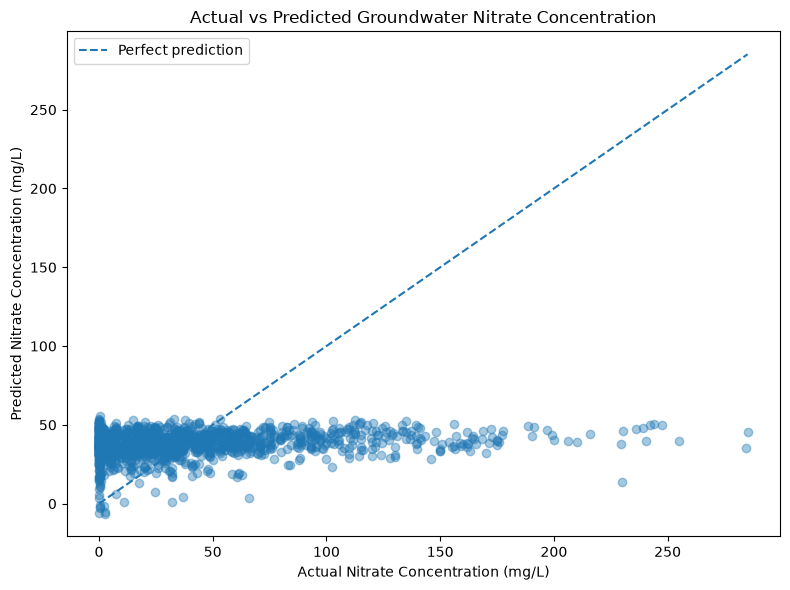

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Nitrate Concentration (mg/L)")
plt.ylabel("Predicted Nitrate Concentration (mg/L)")
plt.title("Actual vs Predicted Groundwater Nitrate Concentration")

plt.legend()
plt.tight_layout()
plt.show()

## Random Forest Regression

Because Linear Regression showed limited predictive performance, a Random Forest Regression model is tested as a simple non-linear alternative.

The same predictor variables and train/test split are used to allow direct comparison between the two models.

In [28]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [29]:
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"Random Forest MAE: {rf_mae:.2f} mg/L")
print(f"Random Forest RMSE: {rf_rmse:.2f} mg/L")
print(f"Random Forest R²: {rf_r2:.3f}")

Random Forest MAE: 5.94 mg/L
Random Forest RMSE: 15.95 mg/L
Random Forest R²: 0.879


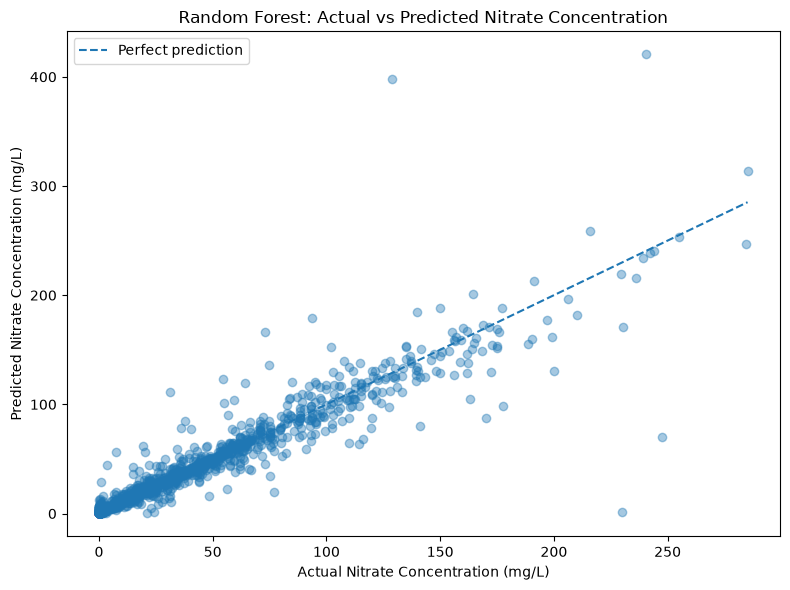

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Nitrate Concentration (mg/L)")
plt.ylabel("Predicted Nitrate Concentration (mg/L)")
plt.title("Random Forest: Actual vs Predicted Nitrate Concentration")

plt.legend()
plt.tight_layout()
plt.show()

## Validation on Unseen Monitoring Stations

Because multiple yearly observations belong to the same monitoring stations, a random row-based train/test split may place observations from the same station in both datasets.

To provide a stricter evaluation, monitoring stations are separated between the training and test sets so that the model is evaluated on stations it has not seen during training.

In [31]:
from sklearn.model_selection import GroupShuffleSplit

groups = df["StationCode"]

group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

print("Training observations:", len(X_train_group))
print("Test observations:", len(X_test_group))

print(
    "Training stations:",
    df.iloc[train_idx]["StationCode"].nunique()
)

print(
    "Test stations:",
    df.iloc[test_idx]["StationCode"].nunique()
)

Training observations: 5840
Test observations: 1471
Training stations: 613
Test stations: 154


In [32]:
rf_group_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_group_model.fit(X_train_group, y_train_group)

rf_group_pred = rf_group_model.predict(X_test_group)

group_mae = mean_absolute_error(y_test_group, rf_group_pred)
group_rmse = np.sqrt(
    mean_squared_error(y_test_group, rf_group_pred)
)
group_r2 = r2_score(y_test_group, rf_group_pred)

print(f"Station-based Random Forest MAE: {group_mae:.2f} mg/L")
print(f"Station-based Random Forest RMSE: {group_rmse:.2f} mg/L")
print(f"Station-based Random Forest R²: {group_r2:.3f}")

Station-based Random Forest MAE: 35.95 mg/L
Station-based Random Forest RMSE: 50.90 mg/L
Station-based Random Forest R²: -0.251


Random Forest achieved high predictive performance with a random observation-based split (R² = 0.879). However, performance dropped substantially when evaluated on completely unseen monitoring stations (R² = −0.251), indicating limited spatial generalization.

Location, year and sampling depth alone are insufficient to reliably predict nitrate concentrations at new monitoring locations.

## Feature Importance

Feature importance from the Random Forest model is used to examine which predictor variables contribute most to the model's predictions.

The results should be interpreted cautiously because high predictive performance in the random split may partly reflect repeated observations from the same monitoring stations.

In [33]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
3,Longitude,0.361425
2,Latitude,0.351478
1,SamplingDepth_m,0.213707
0,Year,0.073390


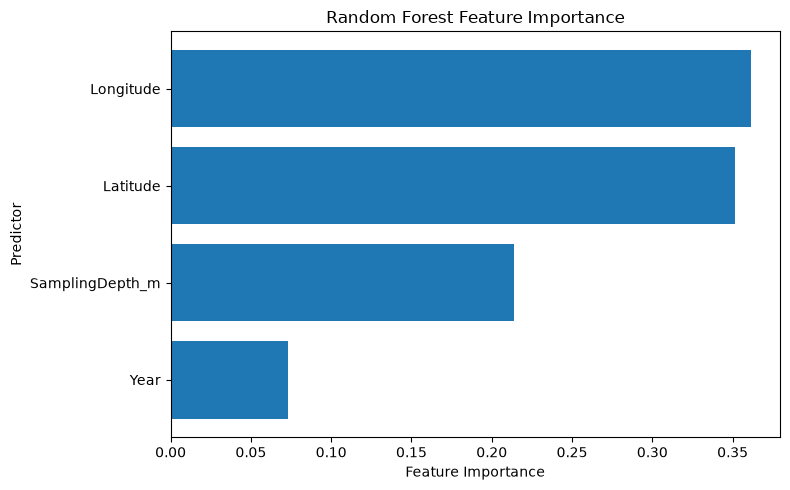

In [34]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Predictor")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Machine Learning Summary

A simple machine learning analysis was conducted to explore whether groundwater nitrate concentration could be predicted using **Year, SamplingDepth_m, Latitude, and Longitude**.

### Linear Regression

The Linear Regression model showed poor predictive performance:

- **MAE:** 33.27 mg/L
- **RMSE:** 45.19 mg/L
- **R²:** 0.032

This indicates that simple linear relationships between the selected predictors and nitrate concentration explain only a small proportion of the observed variation.

### Random Forest Regression

Random Forest substantially improved predictive performance using a standard random train/test split:

- **MAE:** 5.94 mg/L
- **RMSE:** 15.95 mg/L
- **R²:** 0.879

However, because multiple yearly observations originate from the same monitoring stations, this random split may allow the model to learn station-specific spatial patterns.

### Validation on Unseen Monitoring Stations

A stricter station-based train/test split was therefore applied, ensuring that monitoring stations in the test set were not present during model training.

Performance decreased substantially:

- **MAE:** 35.95 mg/L
- **RMSE:** 50.90 mg/L
- **R²:** -0.251

This indicates that the model does not generalize well to completely unseen monitoring locations.

### Feature Importance

Longitude and latitude were the most important predictors in the Random Forest model, followed by sampling depth and year. This suggests that spatial location plays an important role in the model's predictions.

Feature importance should not be interpreted as causality. Latitude and longitude represent spatial location and may indirectly capture environmental or regional factors that are not explicitly included in the dataset.

### Conclusion

The machine learning analysis demonstrates that Random Forest can reproduce nitrate patterns well when observations from known monitoring locations are available. However, its poor performance on unseen stations shows that **year, sampling depth, latitude, and longitude alone are insufficient for reliable prediction at new monitoring locations**.

Additional explanatory variables, such as land use, agricultural intensity, soil characteristics, hydrogeology, and fertilizer application, could potentially improve spatial generalization.